# Sesión 4 — Laboratorio: mezclas gaussianas y k-medias en Iris

Demostración de los modelos de mezclas gaussianas (GMM) con scikit-learn sobre el conjunto Iris
(150 flores, cuatro medidas en centímetros). La especie **no** se usa para ajustar los modelos:
sólo para evaluar al final.

Pasos: ajustar la mezcla, leer las asignaciones suaves, comparar los tipos de covarianza,
elegir el número de componentes con BIC y AIC, y comparar con k-medias.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.datasets import load_iris
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

## Paso 1: ajustar la mezcla

Tres componentes con covarianza completa (`full`) y 10 inicializaciones de EM; se conserva la de
mayor verosimilitud. Como en las sesiones anteriores, las medidas se usan en centímetros sin estandarizar.

In [2]:
X, especie = load_iris(return_X_y=True)

gm = GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=0).fit(X)
print("convergió:", gm.converged_, "| iteraciones:", gm.n_iter_, "| pesos:", gm.weights_.round(2))

z = gm.predict(X)
print(pd.crosstab(z, especie, rownames=["componente"], colnames=["especie"]))
print("ARI contra la especie:", round(adjusted_rand_score(especie, z), 2))

convergió: True | iteraciones: 17 | pesos: [0.3  0.33 0.37]
especie      0   1   2
componente            
0            0  45   0
1           50   0   0
2            0   5  50
ARI contra la especie: 0.9


## Paso 2: asignaciones suaves

`predict_proba` devuelve las responsabilidades: la probabilidad de que cada componente haya
generado cada flor. Las flores con probabilidad máxima baja están en una frontera.

In [3]:
P = gm.predict_proba(X)                      # 150 x 3, cada fila suma 1
print("flores con probabilidad máxima > 0.99:", (P.max(axis=1) > 0.99).sum())

inciertas = np.where(P.max(axis=1) < 0.9)[0]
pd.DataFrame({"especie": np.array(load_iris().target_names)[especie[inciertas]],
              "largo pétalo": X[inciertas, 2], "ancho pétalo": X[inciertas, 3],
              "P(comp. 0)": P[inciertas, 0].round(2), "P(comp. 1)": P[inciertas, 1].round(2),
              "P(comp. 2)": P[inciertas, 2].round(2), "asignada a": z[inciertas]}, index=inciertas)

flores con probabilidad máxima > 0.99: 132


,especie,largo pétalo,ancho pétalo,P(comp. 0),P(comp. 1),P(comp. 2),asignada a
77,versicolor,5.0,1.7,0.37,0.0,0.63,2
84,versicolor,4.5,1.5,0.86,0.0,0.14,0
133,virginica,5.1,1.5,0.24,0.0,0.76,2


## Paso 3: comparar los tipos de covarianza

In [4]:
filas = []
for tipo in ["full", "tied", "diag", "spherical"]:
    g = GaussianMixture(3, covariance_type=tipo, n_init=10, random_state=0).fit(X)
    zt = g.predict(X)
    filas.append((tipo, g._n_parameters(), round(g.bic(X), 1),
                  round(adjusted_rand_score(especie, zt), 2), np.bincount(zt)))
pd.DataFrame(filas, columns=["tipo", "parámetros", "BIC", "ARI", "tamaños"])

,tipo,parámetros,BIC,ARI,tamaños
0,full,44,580.9,0.90,"[45, 50, 55]"
1,tied,24,633.8,0.89,"[52, 50, 48]"
2,diag,26,744.6,0.76,"[36, 50, 64]"
3,spherical,17,853.8,0.73,"[62, 50, 38]"


## Paso 4: elegir $K$ con BIC y AIC

En los dos criterios, menor es mejor.

BIC
     full   tied    diag  spherical
1  830.0  830.0  1522.1     1804.1
2  574.0  688.1   857.6     1012.2
3  580.9  633.8   744.6      853.8
4  622.2  618.0   705.1      783.9
5  669.8  605.0   700.9      742.7
6  683.6  604.8   697.2      705.8 

AIC
     full   tied    diag  spherical
1  787.8  787.8  1498.0     1789.0
2  486.7  630.9   806.4      979.1
3  448.4  561.6   666.4      802.6
4  444.5  530.7   599.7      714.7
5  447.0  502.7   568.5      655.4
6  415.7  487.4   537.6      600.4

Mínimo de BIC: (2, 'full') | mínimo de AIC: (6, 'full')


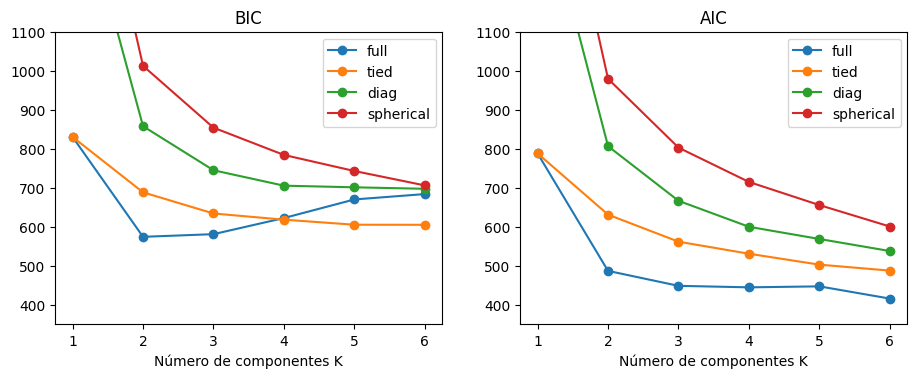

In [5]:
tipos = ["full", "tied", "diag", "spherical"]
ks = range(1, 7)
bic = pd.DataFrame(index=ks, columns=tipos, dtype=float)
aic = pd.DataFrame(index=ks, columns=tipos, dtype=float)
for tipo in tipos:
    for k in ks:
        g = GaussianMixture(k, covariance_type=tipo, n_init=10, random_state=0).fit(X)
        bic.loc[k, tipo], aic.loc[k, tipo] = g.bic(X), g.aic(X)

print("BIC\n", bic.round(1), "\n\nAIC\n", aic.round(1))
print("\nMínimo de BIC:", bic.stack().idxmin(), "| mínimo de AIC:", aic.stack().idxmin())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
bic.plot(ax=axes[0], marker="o", title="BIC"); aic.plot(ax=axes[1], marker="o", title="AIC")
for ax in axes:
    ax.set_xlabel("Número de componentes K"); ax.set_ylim(350, 1100)
plt.show()

## Paso 5: GMM contra k-medias

In [6]:
z_km = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
print(pd.crosstab(z_km, especie, rownames=["grupo k-medias"], colnames=["especie"]))
print("ARI k-medias:", round(adjusted_rand_score(especie, z_km), 2),
      "| ARI GMM:", round(adjusted_rand_score(especie, z), 2))

especie          0   1   2
grupo k-medias            
0                0  48  14
1               50   0   0
2                0   2  36
ARI k-medias: 0.73 | ARI GMM: 0.9


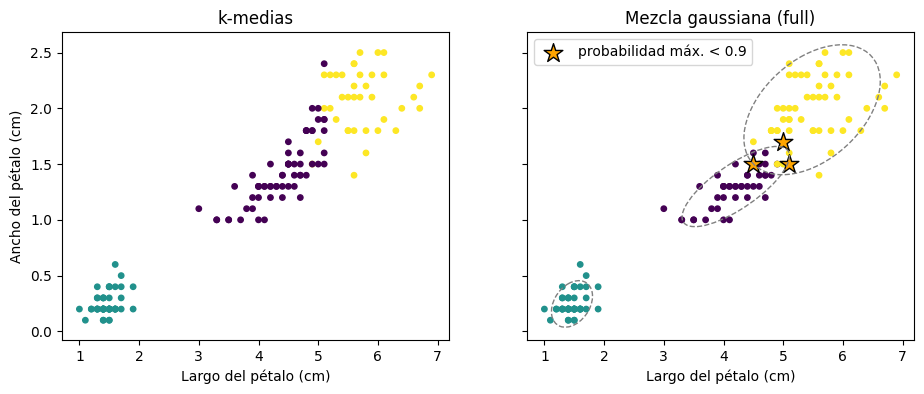

In [7]:
def elipse(ax, media, cov):
    val, vec = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(vec[1, 1], vec[0, 1]))
    ax.add_patch(Ellipse(media, 4 * np.sqrt(val[1]), 4 * np.sqrt(val[0]), angle=ang,
                         fill=False, color="gray", ls="--"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].scatter(X[:, 2], X[:, 3], c=z_km, cmap="viridis", s=15)
axes[0].set_title("k-medias")
axes[1].scatter(X[:, 2], X[:, 3], c=z, cmap="viridis", s=15)
axes[1].scatter(X[inciertas, 2], X[inciertas, 3], marker="*", s=200, color="orange",
                edgecolors="k", label="probabilidad máx. < 0.9")
for m, S in zip(gm.means_, gm.covariances_):
    elipse(axes[1], m[2:], S[2:, 2:])               # proyección en el plano de los pétalos
axes[1].set_title("Mezcla gaussiana (full)"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("Largo del pétalo (cm)")
axes[0].set_ylabel("Ancho del pétalo (cm)")
plt.show()

## Conclusiones

* Con covarianza completa, la mezcla gaussiana se acerca más a las especies que k-medias
  (ARI 0.90 contra 0.73) porque los grupos de Iris son elípticos.
* Las probabilidades indican qué flores están en la frontera entre versicolor y virginica.
* El tipo de covarianza importa: `spherical` se comporta como k-medias.
* BIC elige el tipo de covarianza sin usar etiquetas; para $K$ duda entre 2 y 3.
* AIC elige demasiados componentes cuando el objetivo es contar grupos.